In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def filtroMediana(img, n):
    if isinstance(img, str):
        img = cv2.imread(img, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError("No se pudo leer la imagen.")
        
    filas, columnas = img.shape

    o = n // 2

    salida = np.zeros_like(img)

    for i in range(o, filas - o):
        for j in range(o, columnas - o):
            region = img[i - o:i + o + 1, j - o:j + o + 1]
            mediana = np.median(region)
            salida[i, j] = mediana

    return salida

In [3]:
im_test = np.array([
    [10, 20, 30, 40, 50, 60],
    [15, 25, 35, 45, 55, 65],
    [20, 30, 40, 50, 60, 70],
    [25, 35, 45, 55, 65, 75],
    [30, 40, 50, 60, 70, 80],
    [35, 45, 55, 65, 75, 85]
], dtype=np.uint8)

# Filtros de mediana 3x3 y 5x5
print("Filtro de mediana 3x3:")
print(filtroMediana(im_test, 3))
print("\nFiltro de mediana 5x5:")
print(filtroMediana(im_test, 5))


Filtro de mediana 3x3:
[[ 0  0  0  0  0  0]
 [ 0 25 35 45 55  0]
 [ 0 30 40 50 60  0]
 [ 0 35 45 55 65  0]
 [ 0 40 50 60 70  0]
 [ 0  0  0  0  0  0]]

Filtro de mediana 5x5:
[[ 0  0  0  0  0  0]
 [ 0  0  0  0  0  0]
 [ 0  0 40 50  0  0]
 [ 0  0 45 55  0  0]
 [ 0  0  0  0  0  0]
 [ 0  0  0  0  0  0]]


In [4]:
#TAREA 20

In [6]:
im_random_10 = np.random.randint(0, 256, size=(10, 10), dtype=np.uint8)
im_random_30 = np.random.randint(0, 256, size=(30, 30), dtype=np.uint8)

res_10 = filtroMediana(im_random_10, 3)
res_30 = filtroMediana(im_random_30, 3)

print("=== MATRIZ ALEATORIA 10x10 ===")
print("Matriz original:\n", im_random_10, "\n")
print("Matriz filtrada (3x3):\n", res_10, "\n")

print("=== MATRIZ ALEATORIA 30x30 ===")
print("Matriz original:\n", im_random_30, "\n")
print("Matriz filtrada (3x3):\n", res_30)

=== MATRIZ ALEATORIA 10x10 ===
Matriz original:
 [[192 224 176 109  60 148  15 144  10 139]
 [200 134 212 107 210 166 184   6 148 104]
 [ 65 237 198 237  30  99  87 224  24 195]
 [ 44 254 140  43 194 107  46  31  33 246]
 [140 233   9 242  13  31  49 110 224 231]
 [121 153 230 137 150 188 189  90 138 149]
 [139 247   6  61 129 250 201 233 147 115]
 [ 50 220 189   0   5 181 205 192 127  59]
 [191 223 253 175 233 210 232  44 252  40]
 [ 10  92   2 202 222 128 133 203 230 165]] 

Matriz filtrada (3x3):
 [[  0   0   0   0   0   0   0   0   0   0]
 [  0 198 198 176 109  99 144  87 139   0]
 [  0 198 198 194 107 107  99  46 104   0]
 [  0 140 233 140  99  49  87  49 195   0]
 [  0 140 153 140 137 107  90  90 138   0]
 [  0 140 153 129 137 150 188 147 147   0]
 [  0 153 153 129 137 188 192 189 138   0]
 [  0 191 189 129 175 205 205 201 127   0]
 [  0 189 189 189 181 205 192 203 165   0]
 [  0   0   0   0   0   0   0   0   0   0]] 

=== MATRIZ ALEATORIA 30x30 ===
Matriz original:
 [[ 62 217 24

In [7]:
#TAREA21

In [11]:
def filtro(img, cf):
    if isinstance(img, str):
        img = cv2.imread(img, cv2.IMREAD_GRAYSCALE)
    
    if img is None:
        raise ValueError("No se pudo leer la imagen")

    filas, columnas = img.shape

    m, n = cf.shape
    oF = m // 2
    oC = n // 2

    suma_cf = np.sum(cf)
    if suma_cf != 0:
        cf = cf / suma_cf

    salida = np.zeros_like(img, dtype=float)

    for i in range(oF, filas - oF):
        for j in range(oC, columnas - oC):
            region = img[i - oF:i + oF + 1, j - oC:j + oC + 1]
            salida[i, j] = np.sum(region * cf)

    salida = np.clip(salida, 0, 255).astype(np.uint8)

    return salida

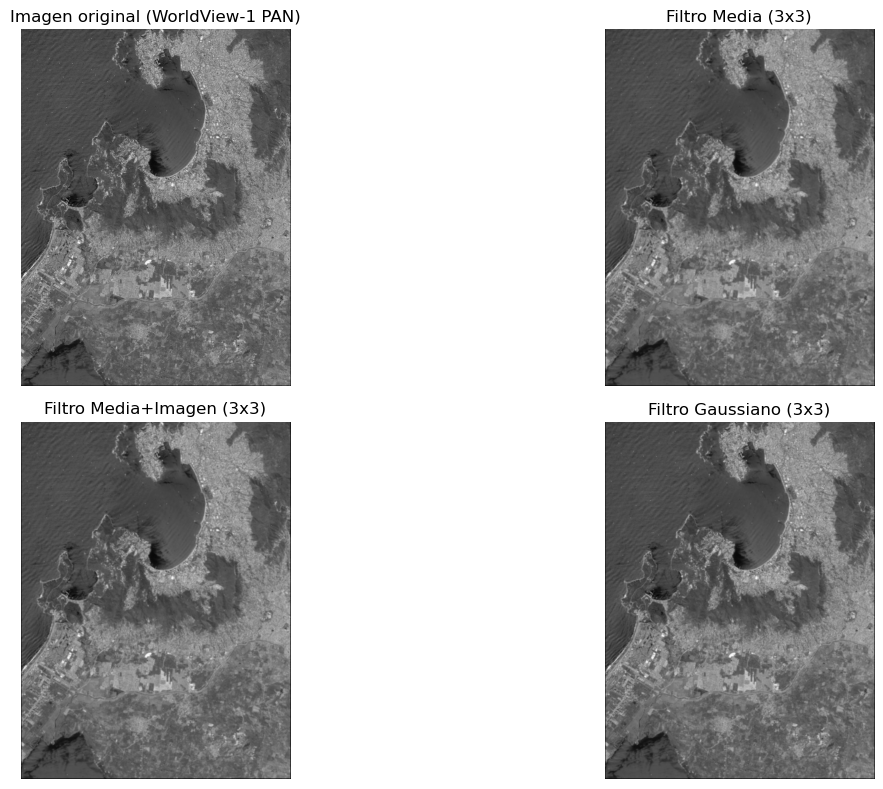

In [12]:
img = cv2.imread("WorldView_1-1_PAN.png", cv2.IMREAD_GRAYSCALE)
if img is None:
    raise ValueError("No se pudo leer la imagen. Verifica el nombre o la ruta.")

filtro_media = np.array([[1, 1, 1],
                         [1, 1, 1],
                         [1, 1, 1]], dtype=float)

filtro_media_img = np.array([[1, 1, 1],
                             [1, 2, 1],
                             [1, 1, 1]], dtype=float)

filtro_gauss = np.array([[1, 2, 1],
                         [2, 4, 2],
                         [1, 2, 1]], dtype=float)

img_media = filtro(img, filtro_media)
img_media_img = filtro(img, filtro_media_img)
img_gauss = filtro(img, filtro_gauss)

plt.figure(figsize=(15,8))

plt.subplot(2,2,1)
plt.imshow(img, cmap='gray')
plt.title("Imagen original (WorldView-1 PAN)")
plt.axis('off')

plt.subplot(2,2,2)
plt.imshow(img_media, cmap='gray')
plt.title("Filtro Media (3x3)")
plt.axis('off')

plt.subplot(2,2,3)
plt.imshow(img_media_img, cmap='gray')
plt.title("Filtro Media+Imagen (3x3)")
plt.axis('off')

plt.subplot(2,2,4)
plt.imshow(img_gauss, cmap='gray')
plt.title("Filtro Gaussiano (3x3)")
plt.axis('off')

plt.tight_layout()
plt.show()
